# LeetCode #490: The Maze

https://leetcode.com/problems/the-maze/

## Comparison of Approaches

| Approach | Time Complexity | Space Complexity |
| :--- | :--- | :--- |
| **DFS with Rolling** | $O(m \cdot n \cdot \max(m,n))$ | $O(m \cdot n)$ |
| **Optimal: BFS with Rolling ★** | $O(m \cdot n \cdot \max(m,n))$ | $O(m \cdot n)$ |

---

## Understanding the Methods

### DFS with Rolling
From the start position, try rolling in all four directions. The ball rolls until it hits a wall, then stops. Mark the stopping position as visited and recurse from there. If we reach the destination, return true.

### Optimal: BFS with Rolling ★
Same idea as DFS but uses BFS. From each position, roll the ball in all four directions until it hits a wall. Add the stopping positions to the queue if not visited. BFS explores positions level by level.

**Why BFS is preferred:** Both have the same complexity, but BFS naturally finds the destination via the shortest number of rolls. The problem only asks reachability, so both work equally well.

**Constraints:**
* m == maze.length, n == maze[i].length
* 1 <= m, n <= 100
* maze[i][j] is 0 or 1
* start.length == destination.length == 2

## Solutions

### C#

In [ ]:
public class Solution {
    public bool HasPath(int[][] maze, int[] start, int[] destination) {
        int m = maze.Length, n = maze[0].Length;
        bool[,] visited = new bool[m, n];
        var queue = new Queue<(int, int)>();
        queue.Enqueue((start[0], start[1]));
        visited[start[0], start[1]] = true;
        int[] dr = {0, 0, 1, -1}, dc = {1, -1, 0, 0};
        while (queue.Count > 0) {
            var (r, c) = queue.Dequeue();
            if (r == destination[0] && c == destination[1]) return true;
            for (int d = 0; d < 4; d++) {
                int nr = r, nc = c;
                while (nr + dr[d] >= 0 && nr + dr[d] < m && nc + dc[d] >= 0 && nc + dc[d] < n && maze[nr + dr[d]][nc + dc[d]] == 0) {
                    nr += dr[d];
                    nc += dc[d];
                }
                if (!visited[nr, nc]) {
                    visited[nr, nc] = true;
                    queue.Enqueue((nr, nc));
                }
            }
        }
        return false;
    }
}

### Python

In [ ]:
from collections import deque

class Solution:
    def hasPath(self, maze: list[list[int]], start: list[int], destination: list[int]) -> bool:
        m, n = len(maze), len(maze[0])
        visited = set()
        visited.add((start[0], start[1]))
        queue = deque([(start[0], start[1])])
        while queue:
            r, c = queue.popleft()
            if [r, c] == destination:
                return True
            for dr, dc in ((0, 1), (0, -1), (1, 0), (-1, 0)):
                nr, nc = r, c
                while 0 <= nr + dr < m and 0 <= nc + dc < n and maze[nr + dr][nc + dc] == 0:
                    nr += dr
                    nc += dc
                if (nr, nc) not in visited:
                    visited.add((nr, nc))
                    queue.append((nr, nc))
        return False

### Go

In [ ]:
func hasPath(maze [][]int, start []int, destination []int) bool {
    m, n := len(maze), len(maze[0])
    visited := make([][]bool, m)
    for i := range visited { visited[i] = make([]bool, n) }
    type pos struct{ r, c int }
    queue := []pos{{start[0], start[1]}}
    visited[start[0]][start[1]] = true
    dirs := [][2]int{{0, 1}, {0, -1}, {1, 0}, {-1, 0}}
    for len(queue) > 0 {
        cur := queue[0]; queue = queue[1:]
        if cur.r == destination[0] && cur.c == destination[1] { return true }
        for _, d := range dirs {
            nr, nc := cur.r, cur.c
            for nr+d[0] >= 0 && nr+d[0] < m && nc+d[1] >= 0 && nc+d[1] < n && maze[nr+d[0]][nc+d[1]] == 0 {
                nr += d[0]; nc += d[1]
            }
            if !visited[nr][nc] {
                visited[nr][nc] = true
                queue = append(queue, pos{nr, nc})
            }
        }
    }
    return false
}

### Rust

In [ ]:
use std::collections::VecDeque;

impl Solution {
    pub fn has_path(maze: Vec<Vec<i32>>, start: Vec<i32>, destination: Vec<i32>) -> bool {
        let (m, n) = (maze.len(), maze[0].len());
        let (sr, sc) = (start[0] as usize, start[1] as usize);
        let (dr, dc) = (destination[0] as usize, destination[1] as usize);
        let mut visited = vec![vec![false; n]; m];
        visited[sr][sc] = true;
        let mut queue = VecDeque::new();
        queue.push_back((sr, sc));
        let dirs: [(i32, i32); 4] = [(0, 1), (0, -1), (1, 0), (-1, 0)];
        while let Some((r, c)) = queue.pop_front() {
            if r == dr && c == dc { return true; }
            for &(di, dj) in &dirs {
                let (mut nr, mut nc) = (r as i32, c as i32);
                while nr + di >= 0 && nr + di < m as i32 && nc + dj >= 0 && nc + dj < n as i32
                    && maze[(nr + di) as usize][(nc + dj) as usize] == 0 {
                    nr += di; nc += dj;
                }
                let (nr, nc) = (nr as usize, nc as usize);
                if !visited[nr][nc] {
                    visited[nr][nc] = true;
                    queue.push_back((nr, nc));
                }
            }
        }
        false
    }
}

## Example Scenarios

### 1. Common Case — Reachable in Seven Rolls

**Input:** `maze = [[0,0,1,0,0],[0,0,0,0,0],[0,0,0,1,0],[1,1,0,1,1],[0,0,0,0,0]], start = [0,4], destination = [4,4]`

The ball cannot be steered mid-roll: from `(0,4)` it rolls left to `(0,3)`, down to `(1,3)`, left all the way to `(1,0)`, down to `(2,0)`, right to `(2,2)`, down to `(4,2)` and finally right into `(4,4)`. BFS reaches the destination in 7 rolls, so the answer is `true`.

### 2. Slightly Complex — Passes Through the Target but Never Stops

**Input:** `maze = [[0,0,1,0,0],[0,0,0,0,0],[0,0,0,1,0],[1,1,0,1,1],[0,0,0,0,0]], start = [0,4], destination = [3,2]`

`(3,2)` is an open cell the ball crosses on the roll from `(2,2)` down to `(4,2)`, but nothing stops it there — the only two walls in that column are above `(2,2)` and below `(4,2)`. BFS enumerates all 15 reachable *stop* cells and `(3,2)` is not one of them, so the answer is `false`. This is the trap: reachability means *stoppable*, not merely *traversable*.

### 3. Edge Case: Time Factor — Open Grid, Every Roll Crosses the Whole Board

**Input:** `maze = [[0,0,0,0,0],[0,0,0,0,0],[0,0,0,0,0],[0,0,0,0,0],[0,0,0,0,0]], start = [0,0], destination = [4,4]`

With no interior walls each roll runs the full length of the board, so a single BFS pop costs $O(\max(m,n))$ per direction — the source of the $O(m \cdot n \cdot \max(m,n))$ bound. Only the four corners are ever stop cells, so the ball reaches `(4,4)` in 2 rolls: `true`.

### 4. Edge Case: Space Factor — Nearly Every Cell Is a Stop

**Input:** `maze = [[0,1,0,0,0],[0,0,0,0,1],[0,0,1,0,0],[1,0,0,0,0],[0,0,0,1,0]], start = [0,0], destination = [4,4]`

Scattered walls turn 19 of the 25 cells into reachable stop positions, so the `visited` set and the BFS queue both approach $O(m \cdot n)$ — the peak-memory shape of the problem. The ball still gets home in 7 rolls: `true`.

### 5. Almost-Impossible but Plausible — Start Equals Destination

**Input:** `maze = [[0]], start = [0,0], destination = [0,0]`

A $1 \times 1$ board where the ball is already at the target. Zero rolls happen, so the destination test must run when a cell is *dequeued* (or before the loop) rather than only after a roll — otherwise the answer is wrongly `false`. Correct output: `true`.


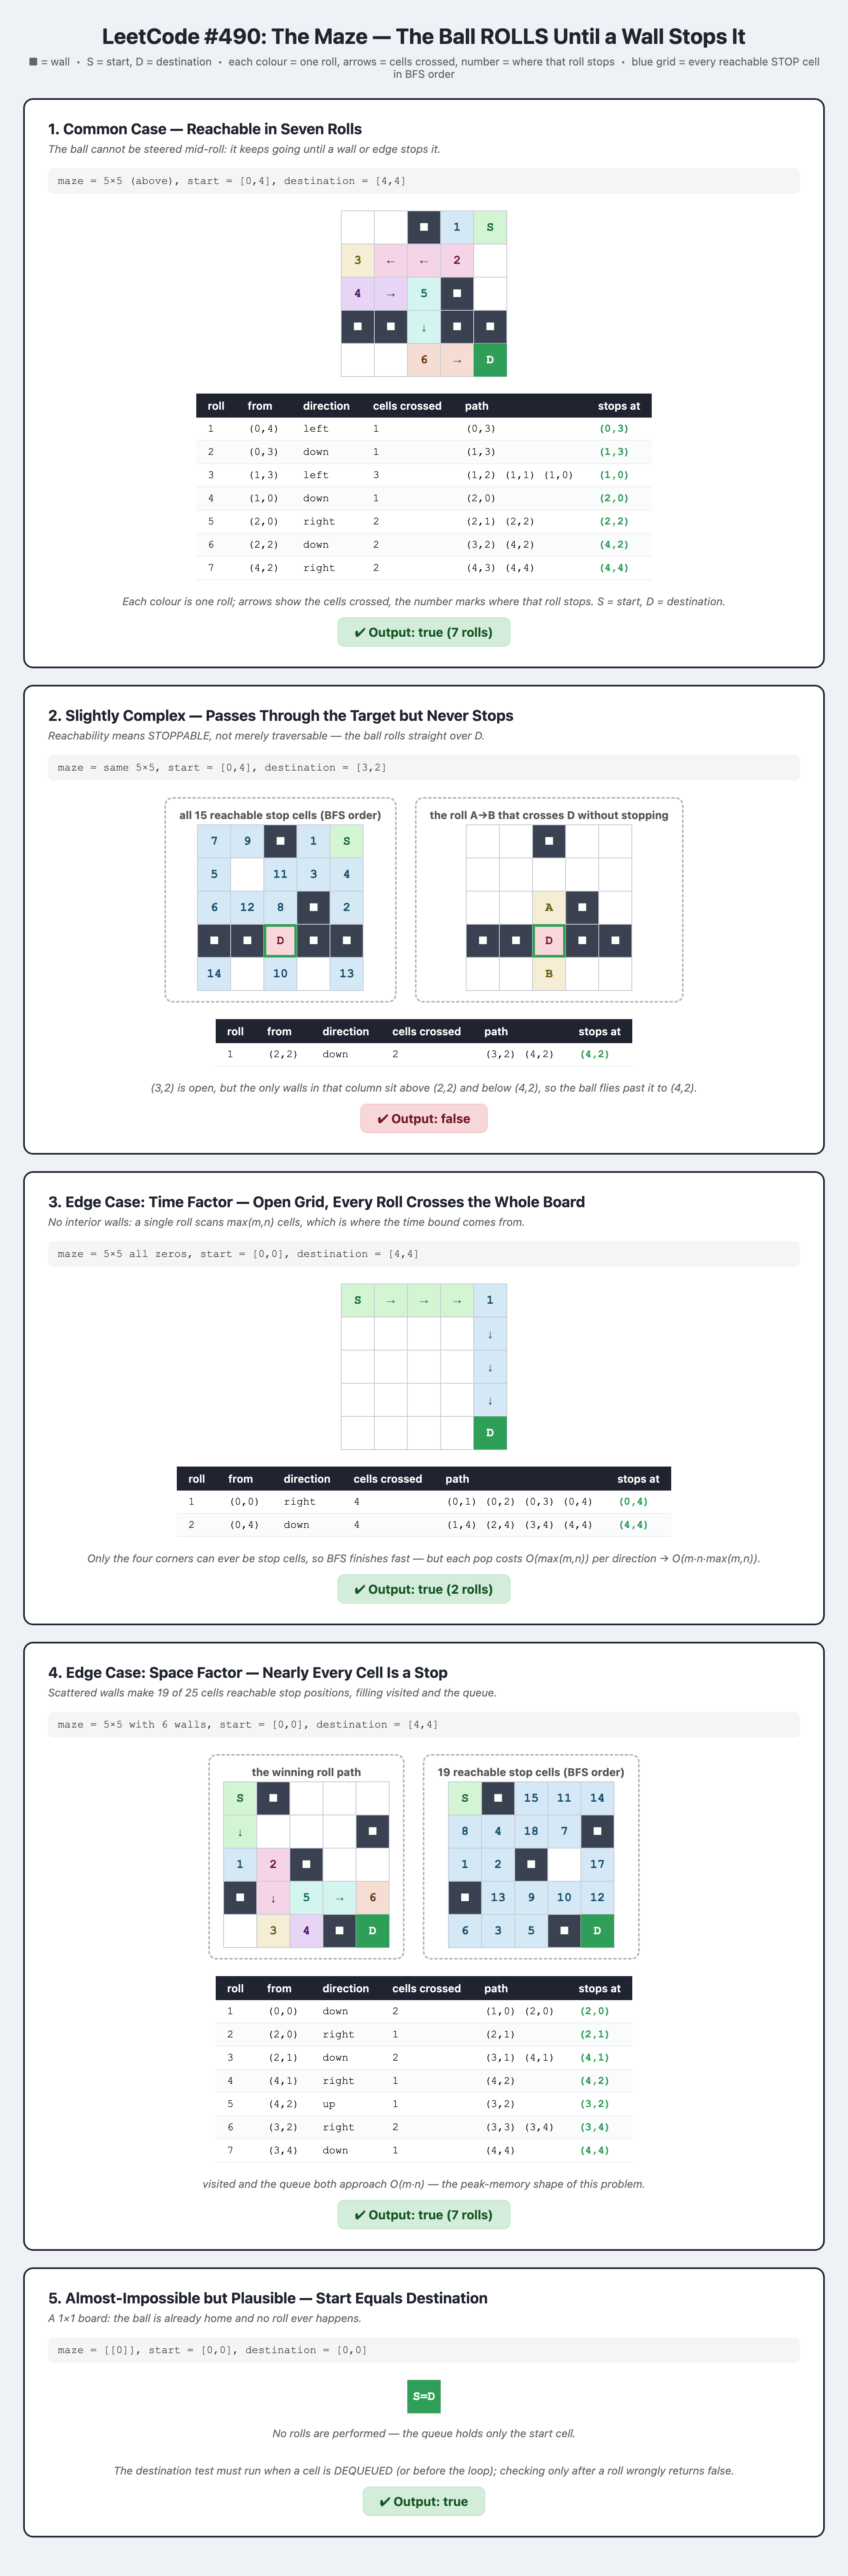